# Ticket 2 ride by ram and fati

## Explore and check the data first

In [3]:
import pandas as pd

df = pd.read_csv("data/passagierfrequenz.csv", sep=";")

df.head()

,Code_Codice,UIC,Bahnhof_Gare_Stazione,Kt_Ct_Cantone,ISB_GI,Jahr_Annee_Anno,DTV_TJM_TGM,DWV_TMJO_TFM,DNWV_TMJNO_TMGNL,EVU_EF_ITF,Bemerkungen,Remarques,Note,Remarks,LOD,geopos
0,AA,8502113.0,Aarau,AG,SBB,2018,37900.0,44800.0,22700.0,SBB,Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
1,AA,8502113.0,Aarau,AG,SBB,2023,37700.0,43400.0,24700.0,"SBB, SOB",Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
2,AA,8502113.0,Aarau,AG,SBB,2024,39000.0,45300.0,24800.0,"SBB, SOB",Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
3,AA,8502113.0,Aarau,AG,SBB,2025,40100.0,46600.0,25700.0,"SBB, SOB",Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
4,AAT,8503124.0,Aathal,ZH,SBB,2022,690.0,750.0,570.0,SBB,NaN,NaN,NaN,NaN,http://lod.opentransportdata.swiss/didok/didok85,"47.3359591338364, 8.765625135347072"


In [4]:
df.shape

(5724, 16)

In [3]:
df.columns.tolist()

['Code_Codice',
 'UIC',
 'Bahnhof_Gare_Stazione',
 'Kt_Ct_Cantone',
 'ISB_GI',
 'Jahr_Annee_Anno',
 'DTV_TJM_TGM',
 'DWV_TMJO_TFM',
 'DNWV_TMJNO_TMGNL',
 'EVU_EF_ITF',
 'Bemerkungen',
 'Remarques',
 'Note',
 'Remarks',
 'LOD',
 'geopos']

In [4]:
df["Jahr_Annee_Anno"].unique()

array([2018, 2023, 2024, 2025, 2022])

In [5]:
df.isnull().sum()

Code_Codice                 0
UIC                         0
Bahnhof_Gare_Stazione       0
Kt_Ct_Cantone               0
ISB_GI                      0
Jahr_Annee_Anno             0
DTV_TJM_TGM                 0
DWV_TMJO_TFM                0
DNWV_TMJNO_TMGNL            0
EVU_EF_ITF                  0
Bemerkungen              5057
Remarques                5057
Note                     5057
Remarks                  5057
LOD                        15
geopos                     15
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.duplicated(
    subset=["UIC", "Jahr_Annee_Anno"]
).sum()

np.int64(0)

In [8]:
df_2025 = df[df["Jahr_Annee_Anno"] == 2025]

df_2025.shape

(1095, 16)

In [9]:
top10 = df_2025.sort_values(
    by="DTV_TJM_TGM",
    ascending=False
).head(10)

top10[["Bahnhof_Gare_Stazione", "DTV_TJM_TGM"]]

,Bahnhof_Gare_Stazione,DTV_TJM_TGM
5712,Zürich HB,449800.0
105,Bern,177000.0
4038,Luzern,108800.0
3562,Basel SBB,103800.0
2238,Winterthur,103800.0
4021,Lausanne,97500.0
5707,Zürich Oerlikon,86200.0
4914,Genève,83100.0
744,Olten,81600.0
1140,Zürich Stadelhofen,75200.0


## 1. Find the busiest stations

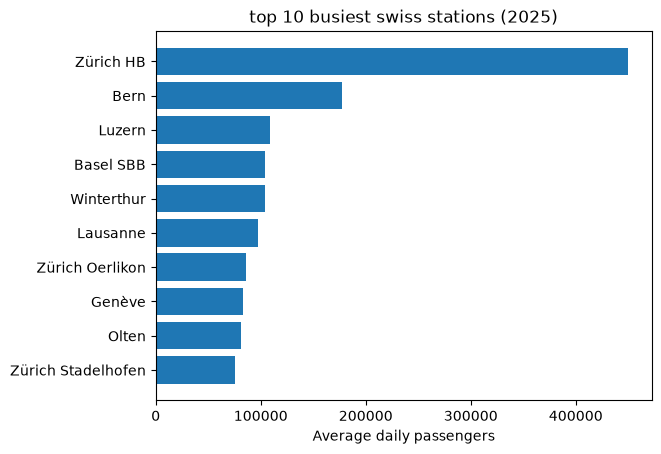

In [16]:
import matplotlib.pyplot as plt
plt.barh(
    top10["Bahnhof_Gare_Stazione"],
    top10["DTV_TJM_TGM"]
)
plt.xlabel("Average daily passengers") 
plt.title("top 10 busiest swiss stations (2025)")
plt.gca().invert_yaxis()

plt.show()

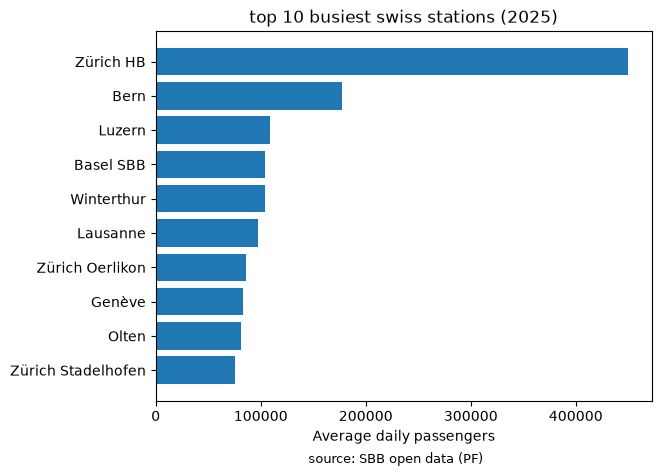

In [20]:
import matplotlib.pyplot as plt
plt.barh(
    top10["Bahnhof_Gare_Stazione"],
    top10["DTV_TJM_TGM"]
)
plt.xlabel("Average daily passengers") 
plt.title("top 10 busiest swiss stations (2025)")
plt.gca().invert_yaxis()

#add our source 
plt.figtext(
    0.5, -0.02,
    "source: SBB open data (PF)",
    ha="center",
    fontsize=9
) 
plt.show()


## 2. Cornavin's story

In [5]:
geneva = df[df["Bahnhof_Gare_Stazione"]=="Genève"]
geneva = geneva.sort_values("Jahr_Annee_Anno") 
geneva[["Jahr_Annee_Anno","DTV_TJM_TGM"]]

,Jahr_Annee_Anno,DTV_TJM_TGM
2647,2018,60500.0
3818,2022,66900.0
2648,2023,79500.0
364,2024,80600.0
4914,2025,83100.0


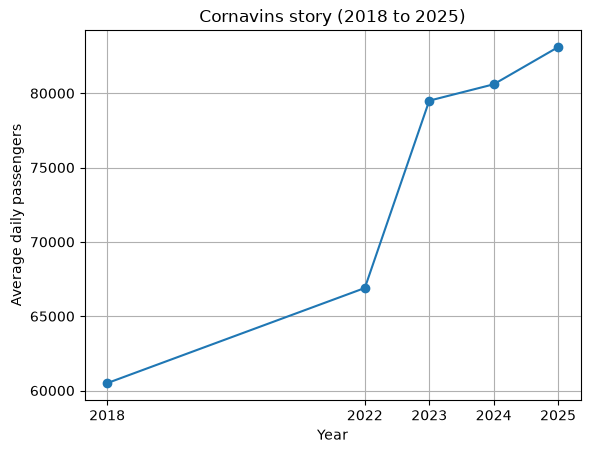

In [6]:
import matplotlib.pyplot as plt

plt.plot(
    geneva["Jahr_Annee_Anno"],
    geneva["DTV_TJM_TGM"],
    marker="o"
)

plt.title("Cornavins story (2018 to 2025)")
plt.xlabel("Year") 
plt.ylabel("Average daily passengers")
plt.xticks(geneva["Jahr_Annee_Anno"])
plt.grid(True)
plt.show()

In [8]:
geneva["Growth%"
    ] = geneva["DTV_TJM_TGM"].pct_change() * 100
geneva[["Jahr_Annee_Anno", "DTV_TJM_TGM", "Growth%"]]

,Jahr_Annee_Anno,DTV_TJM_TGM,Growth%
2647,2018,60500.0,NaN
3818,2022,66900.0,10.578512
2648,2023,79500.0,18.834081
364,2024,80600.0,1.383648
4914,2025,83100.0,3.101737


### Findings 
Passenger traffic at Cornavin increased from 60k average daily passengers in 2018 to 83k in 2025, that is a huge growth and it's almost 37,4% average increase. Also, the largest increase from one year to another happened in the year 23-23 (with +18.83%). Growth then slowed to 1.38% in 2024 and then reached 3.10% in 2025.
We couldn't analyse 2019, 2020, 2021 because the dataset didnt include them (they're missing). 